['x_train', 'x_test', 'y_train', 'y_test']
x_train: (80000, 28, 28, 3)
y_train: (80000,)
x_test: (20000, 28, 28, 3)
y_test: (20000,)
Tipo de x_train: int16
Tipo de y_train: int8
Valores de y_train: [0 1 2 3 4 5 6 7 8 9]


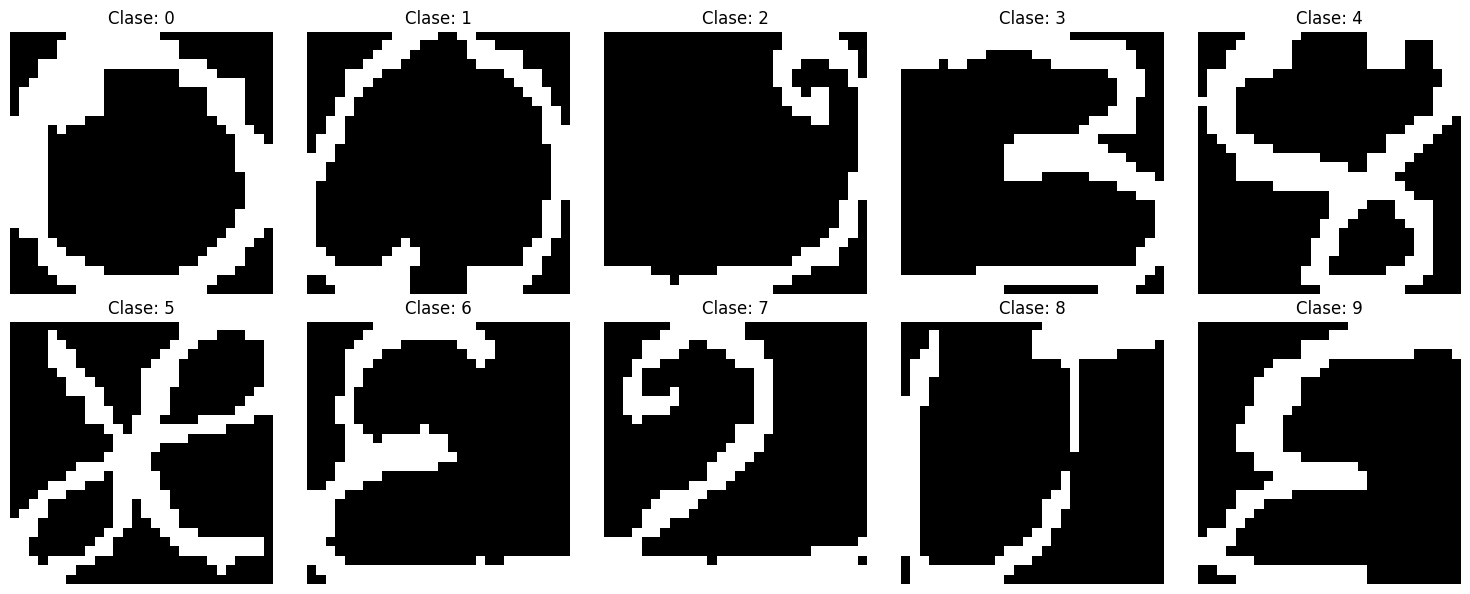

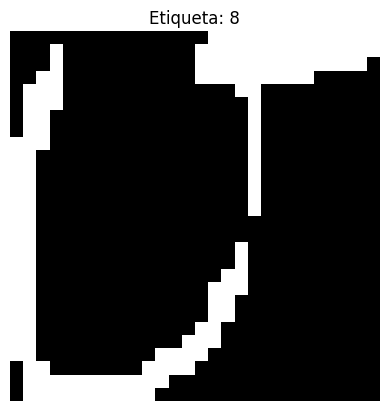

Mínimo: 0
Máximo: 255
Promedio: 66.92686396683673
[0 0 0]
True
True


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

data = np.load('/content/drive/MyDrive/Colab Notebooks/Telugu-optimized.npz')

print(data.files)

x_train = data['x_train']
y_train = data['y_train']

x_test = data['x_test']
y_test = data['y_test']

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

print("Tipo de x_train:", x_train.dtype)
print("Tipo de y_train:", y_train.dtype)

print("Valores de y_train:", np.unique(y_train))


# Obtener las clases únicas presentes en y_train
unique_classes = np.unique(y_train)

# Configurar la cuadrícula de matplotlib (adaptando según la cantidad de clases)
num_classes = len(unique_classes)
cols = 5
rows = int(np.ceil(num_classes / cols))

plt.figure(figsize=(15, 3 * rows))

for i, cls in enumerate(unique_classes):
    # Encontrar el primer índice donde la etiqueta coincide con la clase actual
    idx = np.where(y_train == cls)[0][0]

    plt.subplot(rows, cols, i + 1)
    plt.imshow(x_train[idx], cmap='gray')
    plt.title(f"Clase: {cls}")
    plt.axis('off')

plt.tight_layout()
plt.show()





plt.imshow(x_train[1], cmap='gray')
plt.title(f"Etiqueta: {y_train[1]}")
plt.axis('off')
plt.show()

print("Mínimo:", x_train.min())
print("Máximo:", x_train.max())
print("Promedio:", x_train.mean())

print(x_train[0, 10, 10])

print(np.array_equal(x_train[:, :, :, 0],
                     x_train[:, :, :, 1]))

print(np.array_equal(x_train[:, :, :, 1],
                     x_train[:, :, :, 2]))
#True True
#significaría que los tres canales contienen exactamente la misma información, por lo que en realidad podríamos trabajar con una imagen de un solo canal.

**normalización**

(facilita el entrenamiento de la red neuronal)

X'normalizado = x/255

*   0     → 0.0
*   128   → 0.502
*   255   → 1.0





In [ ]:
#Verificacion de dataset balanceado
print("Distribución en train:")
print(np.bincount(y_train))

print("\nDistribución en test:")
print(np.bincount(y_test))

Distribución en train:
[7997 7991 8005 8020 7974 8005 7980 8053 8000 7975]

Distribución en test:
[2003 2009 1995 1980 2026 1995 2020 1947 2000 2025]


Si el dataset no estuviera balanceado, podriamos tener casos en los que el 90% de nuestro dataset sea una sola clase, el modelo aprende esa clase unicamente y las demas no las reconoce, y nuestro Accuracy = 90%

### Entrada

Una imagen:

$$
28 \times 28 \times 3
$$

que contiene valores de píxeles entre `0` y `255`.

Cada muestra tiene:

$$
28 \times 28 \times 3 = 2352
$$

valores de entrada.

### Salida

Una etiqueta:

$$
y \in \{0,1,2,3,4,5,6,7,8,9\}
$$

# 3. `Flatten`

es una layer que agarra nuestros datos de varias dimensiones y lo arregla en un vector, en esta capa no se aprende.

```text
28 × 28 × 3
```

Flatten lo transforma en:

```text
2352
```

---

# 4. `Dense`

Cuando llegamos a `Dense`, **ya no estamos trabajando directamente con la imagen original**.

Las `Dense` reciben las características que las capas anteriores fueron extrayendo.

> "Dadas todas estas características detectadas, ¿qué combinación corresponde a cada dígito?"

Trabaja **globalmente**.

Después de `Flatten`, tiene acceso a todas las características:

```text
[feature 1, feature 2, feature 3, ..., feature N]
```

y aprende relaciones entre ellas.


In [ ]:
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
# Normalizamos
print("x_train max:", x_train.max())
x_train = x_train / 255.0
x_test = x_test / 255.0

# Versión de un solo canal
x_train_gray = x_train[:, :, :, 0:1] #como todos los canales iguales vamos a probar algunas CNN con un solo canal
x_test_gray = x_test[:, :, :, 0:1]

# Preparamos y_train e y_test para usar One Hot Encoding
y_train_one_hot = to_categorical(y_train, num_classes=10)
y_test_one_hot = to_categorical(y_test, num_classes=10)
#print(y_train[0])
#print(y_train_one_hot[0])


print("x_train:", x_train.shape)
print("x_train_gray:", x_train_gray.shape)

print("y_train:", y_train.shape)
print("y_train_one_hot:", y_train_one_hot.shape)

print("x_train min:", x_train.min())
print("x_train max:", x_train.max())

print("Ejemplo de y:")
print(y_train[0])
print(y_train_one_hot[0])


# Validation
# Separamos de los 80k 72 para entrenamiento 8 para validacion y despues los 20 de test.
# x_train_new, x_val = np.split(x_train, [72000]) #Esto agarra por orden y como no sabemos como estan los datos podes correr riesgo de q no esten bien distribuidos.

indices = np.arange(len(x_train))

indices_train, indices_val = train_test_split(
    indices,
    test_size=0.10, #10% de los 80.000 datos
    random_state=42, #semilla de aleatoriedad
    stratify=y_train #para mantener el balance de las clases
)
# RGB
x_train_final = x_train[indices_train]
x_val = x_train[indices_val]

# Grayscale
x_train_gray_final = x_train_gray[indices_train]
x_val_gray = x_train_gray[indices_val]

# Etiquetas One-Hot
y_train_final = y_train_one_hot[indices_train]
y_val = y_train_one_hot[indices_val]

print(x_train_final.shape)
print(x_val.shape)

print(x_train_gray_final.shape)
print(x_val_gray.shape)

print(y_train_final.shape)
print(y_val.shape)

x_train max: 255
x_train: (80000, 28, 28, 3)
x_train_gray: (80000, 28, 28, 1)
y_train: (80000,)
y_train_one_hot: (80000, 10)
x_train min: 0.0
x_train max: 1.0
Ejemplo de y:
3
[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
(72000, 28, 28, 3)
(8000, 28, 28, 3)
(72000, 28, 28, 1)
(8000, 28, 28, 1)
(72000, 10)
(8000, 10)


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model_MLP_1 = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_MLP_1.compile(
    optimizer='adam', # Es el algoritmo que va modificando los pesos de la red para reducir el error.
    loss='categorical_crossentropy', # Es la función que mide qué tan diferente es: predicción de la red de: etiqueta One-Hot correcta
    metrics=['accuracy'] #Le pedimos a Keras que registre accuracy durante el entrenamiento.
)

model_MLP_1.summary()

history_mlp = model_MLP_1.fit(
    x_train_gray_final, y_train_final,
    validation_data=(x_val_gray, y_val),
    epochs=20, batch_size=128
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9847 - loss: 0.0583 - val_accuracy: 0.9998 - val_loss: 0.0031
Epoch 2/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9994 - loss: 0.0023 - val_accuracy: 0.9991 - val_loss: 0.0047
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9977 - loss: 0.0074 - val_accuracy: 0.9983 - val_loss: 0.0055
Epoch 4/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9995 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 1.5917e-04
Epoch 5/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 1.0000 - loss: 1.4046e-04 - val_accuracy: 1.0000 - val_loss: 4.9311e-05
Epoch 6/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 1.0000 - loss: 2.8850e-05 - val_accuracy: 1.0000 - val_loss: 3.2426e-05
Epoch 7/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 1.0000 - loss: 1.8420e-05 - val_accuracy: 1.0000 - val_loss: 2.4032e-05
Epoch 8/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 1.0000 -

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 1.0960e-06
Precisión en el conjunto de prueba: 1.0. Pérdida: 1.096016490009788e-06
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


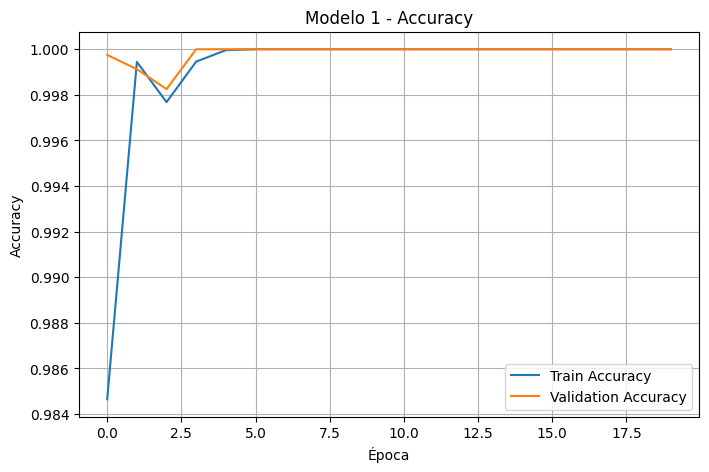

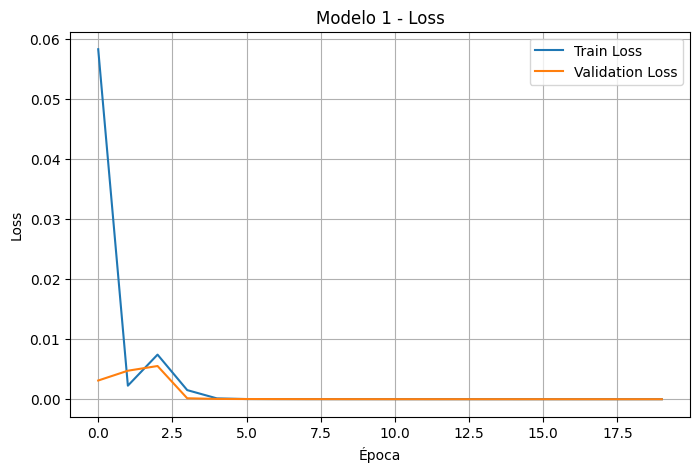

Época  1 | Train Acc: 0.9847 | Val Acc: 0.9998 | Train Loss: 0.058302 | Val Loss: 0.003117
Época  2 | Train Acc: 0.9994 | Val Acc: 0.9991 | Train Loss: 0.002257 | Val Loss: 0.004749
Época  3 | Train Acc: 0.9977 | Val Acc: 0.9983 | Train Loss: 0.007429 | Val Loss: 0.005532
Época  4 | Train Acc: 0.9995 | Val Acc: 1.0000 | Train Loss: 0.001518 | Val Loss: 0.000159
Época  5 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000140 | Val Loss: 0.000049
Época  6 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000029 | Val Loss: 0.000032
Época  7 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000018 | Val Loss: 0.000024
Época  8 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000013 | Val Loss: 0.000017
Época  9 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000009 | Val Loss: 0.000013
Época 10 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000007 | Val Loss: 0.000010
Época 11 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000005 | Val Loss: 0.000008

In [ ]:
test_loss, test_acc = model_MLP_1.evaluate(
    x_test_gray,
    y_test_one_hot
)

print(f'Precisión en el conjunto de prueba: {test_acc}. Pérdida: {test_loss}')

print(history_mlp.history.keys())

plt.figure(figsize=(8, 5))

plt.plot(history_mlp.history['accuracy'], label='Train Accuracy')
plt.plot(history_mlp.history['val_accuracy'], label='Validation Accuracy')

plt.title('Modelo 1 - Accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

#Loss
plt.figure(figsize=(8, 5))

plt.plot(history_mlp.history['loss'], label='Train Loss')
plt.plot(history_mlp.history['val_loss'], label='Validation Loss')

plt.title('Modelo 1 - Loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

#Eoch comparison
for epoch in range(len(history_mlp.history['accuracy'])):
    print(
        f"Época {epoch+1:2d} | "
        f"Train Acc: {history_mlp.history['accuracy'][epoch]:.4f} | "
        f"Val Acc: {history_mlp.history['val_accuracy'][epoch]:.4f} | "
        f"Train Loss: {history_mlp.history['loss'][epoch]:.6f} | "
        f"Val Loss: {history_mlp.history['val_loss'][epoch]:.6f}"
    )

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      2003
           1     1.0000    1.0000    1.0000      2009
           2     1.0000    1.0000    1.0000      1995
           3     1.0000    1.0000    1.0000      1980
           4     1.0000    1.0000    1.0000      2026
           5     1.0000    1.0000    1.0000      1995
           6     1.0000    1.0000    1.0000      2020
           7     1.0000    1.0000    1.0000      1947
           8     1.0000    1.0000    1.0000      2000
           9     1.0000    1.0000    1.0000      2025

    accuracy                         1.0000     20000
   macro avg     1.0000    1.0000    1.0000     20000
weighted avg     1.0000    1.0000    1.0000     20000



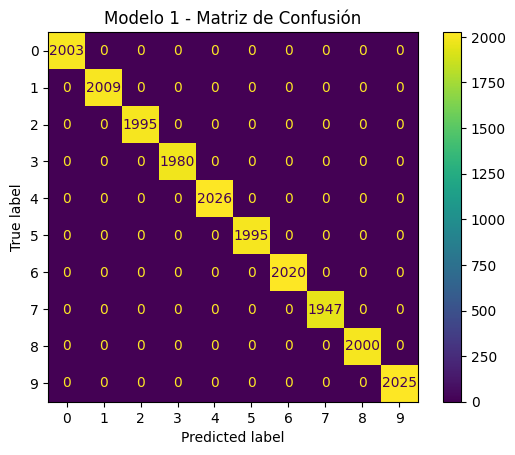

In [ ]:
y_pred_prob1 = model_MLP_1.predict(x_test_gray)
import numpy as np

y_pred = np.argmax(y_pred_prob1, axis=1)
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


print(classification_report(
    y_test,
    y_pred,
    digits=4
))



cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title('Modelo 1 - Matriz de Confusión')
plt.show()

In [ ]:

model_MLP_2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(512, activation='tanh'),
    layers.Dense(256, activation='tanh'),
    layers.Dense(128, activation='tanh'),
    layers.Dense(10, activation='softmax')
])

model_MLP_2.compile(
    optimizer='adam', # Es el algoritmo que va modificando los pesos de la red para reducir el error.
    loss='categorical_crossentropy', # Es la función que mide qué tan diferente es: predicción de la red de: etiqueta One-Hot correcta
    metrics=['accuracy'] #Le pedimos a Keras que registre accuracy durante el entrenamiento.
)

model_MLP_2.summary()

history_mlp_2 = model_MLP_2.fit(
    x_train_gray_final, y_train_final,
    validation_data=(x_val_gray, y_val),
    epochs=20, batch_size=128
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9880 - loss: 0.0451 - val_accuracy: 0.9949 - val_loss: 0.0156
Epoch 2/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9994 - loss: 0.0031 - val_accuracy: 0.9999 - val_loss: 7.9957e-04
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - accuracy: 0.9973 - loss: 0.0085 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 4/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9997 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 2.3790e-04
Epoch 5/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 19s 19ms/step - accuracy: 1.0000 - loss: 1.0458e-04 - val_accuracy: 1.0000 - val_loss: 9.1213e-05
Epoch 6/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 24s 25ms/step - accuracy: 1.0000 - loss: 5.7080e-05 - val_accuracy: 1.0000 - val_loss: 5.7266e-05
Epoch 7/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 1.0000 - loss: 3.8098e-05 - val_accuracy: 1.0000 - val_loss: 4.0241e-05
Epoch 8/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accu

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 1.0000 - loss: 9.7904e-06
Precisión en el conjunto de prueba: 1.0. Pérdida: 9.790403055376373e-06
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


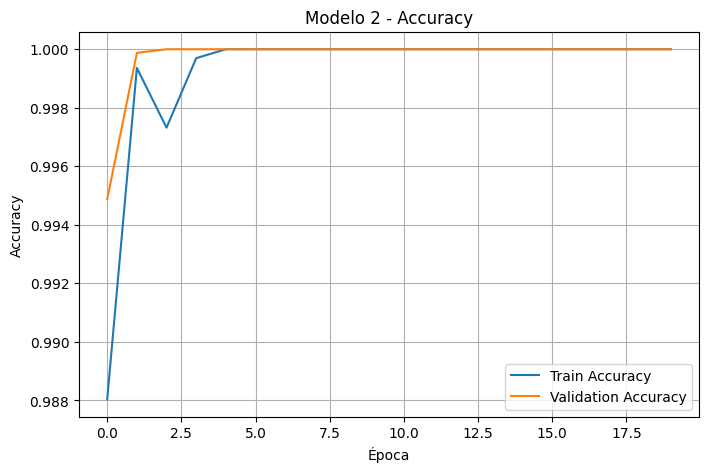

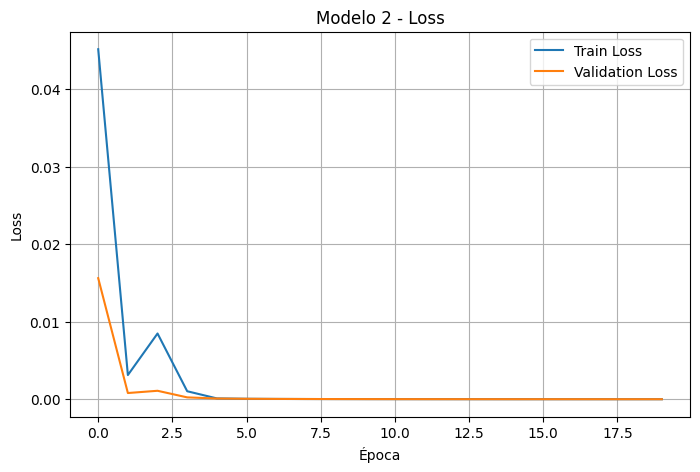

Época  1 | Train Acc: 0.9880 | Val Acc: 0.9949 | Train Loss: 0.045125 | Val Loss: 0.015609
Época  2 | Train Acc: 0.9994 | Val Acc: 0.9999 | Train Loss: 0.003118 | Val Loss: 0.000800
Época  3 | Train Acc: 0.9973 | Val Acc: 1.0000 | Train Loss: 0.008475 | Val Loss: 0.001089
Época  4 | Train Acc: 0.9997 | Val Acc: 1.0000 | Train Loss: 0.001030 | Val Loss: 0.000238
Época  5 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000105 | Val Loss: 0.000091
Época  6 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000057 | Val Loss: 0.000057
Época  7 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000038 | Val Loss: 0.000040
Época  8 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000027 | Val Loss: 0.000029
Época  9 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000019 | Val Loss: 0.000021
Época 10 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000014 | Val Loss: 0.000016
Época 11 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000011 | Val Loss: 0.000012

In [ ]:
test_loss_2, test_acc_2 = model_MLP_2.evaluate(
    x_test_gray,
    y_test_one_hot
)

print(f'Precisión en el conjunto de prueba: {test_acc_2}. Pérdida: {test_loss_2}')

print(history_mlp.history.keys())

plt.figure(figsize=(8, 5))

plt.plot(history_mlp.history['accuracy'], label='Train Accuracy')
plt.plot(history_mlp.history['val_accuracy'], label='Validation Accuracy')

plt.title('Modelo 2 - Accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

#Loss
plt.figure(figsize=(8, 5))

plt.plot(history_mlp.history['loss'], label='Train Loss')
plt.plot(history_mlp.history['val_loss'], label='Validation Loss')

plt.title('Modelo 2 - Loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

#Eoch comparison
for epoch in range(len(history_mlp.history['accuracy'])):
    print(
        f"Época {epoch+1:2d} | "
        f"Train Acc: {history_mlp.history['accuracy'][epoch]:.4f} | "
        f"Val Acc: {history_mlp.history['val_accuracy'][epoch]:.4f} | "
        f"Train Loss: {history_mlp.history['loss'][epoch]:.6f} | "
        f"Val Loss: {history_mlp.history['val_loss'][epoch]:.6f}"
    )

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      2003
           1     1.0000    1.0000    1.0000      2009
           2     1.0000    1.0000    1.0000      1995
           3     1.0000    1.0000    1.0000      1980
           4     1.0000    1.0000    1.0000      2026
           5     1.0000    1.0000    1.0000      1995
           6     1.0000    1.0000    1.0000      2020
           7     1.0000    1.0000    1.0000      1947
           8     1.0000    1.0000    1.0000      2000
           9     1.0000    1.0000    1.0000      2025

    accuracy                         1.0000     20000
   macro avg     1.0000    1.0000    1.0000     20000
weighted avg     1.0000    1.0000    1.0000     20000



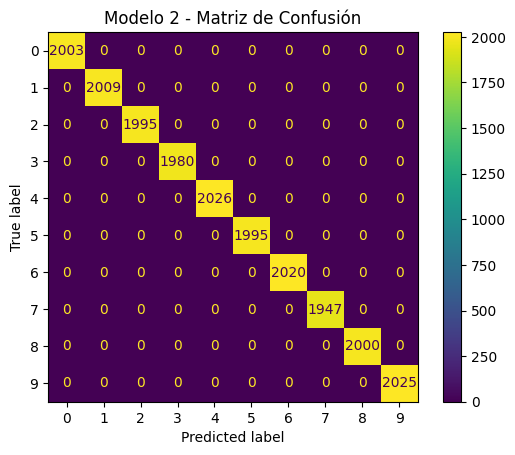

In [ ]:
y_pred_prob2 = model_MLP_2.predict(x_test_gray)
import numpy as np

y_pred = np.argmax(y_pred_prob2, axis=1)
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


print(classification_report(
    y_test,
    y_pred,
    digits=4
))



cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title('Modelo 2 - Matriz de Confusión')
plt.show()

In [ ]:
model_MLP_3 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(128, activation='sigmoid'),
    layers.Dense(64, activation='sigmoid'),
    layers.Dense(10, activation='softmax')
])

model_MLP_3.compile(
    optimizer='adam', # Es el algoritmo que va modificando los pesos de la red para reducir el error.
    loss='categorical_crossentropy', # Es la función que mide qué tan diferente es: predicción de la red de: etiqueta One-Hot correcta
    metrics=['accuracy'] #Le pedimos a Keras que registre accuracy durante el entrenamiento.
)

model_MLP_3.summary()

history_mlp_3 = model_MLP_3.fit(
    x_train_gray_final, y_train_final,
    validation_data=(x_val_gray, y_val),
    epochs=20, batch_size=128
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9370 - loss: 0.4057 - val_accuracy: 0.9900 - val_loss: 0.0663
Epoch 2/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9959 - loss: 0.0348 - val_accuracy: 0.9990 - val_loss: 0.0175
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9995 - loss: 0.0113 - val_accuracy: 1.0000 - val_loss: 0.0074
Epoch 4/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9999 - loss: 0.0051 - val_accuracy: 0.9998 - val_loss: 0.0043
Epoch 5/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 1.0000 - loss: 0.0027 - val_accuracy: 0.9999 - val_loss: 0.0027
Epoch 6/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 7/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 8/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 1.0000 - loss: 6.6072e-04 - val_accurac

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9999 - loss: 1.2110e-04
Precisión en el conjunto de prueba: 0.9999499917030334. Pérdida: 0.00012109986710129306
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


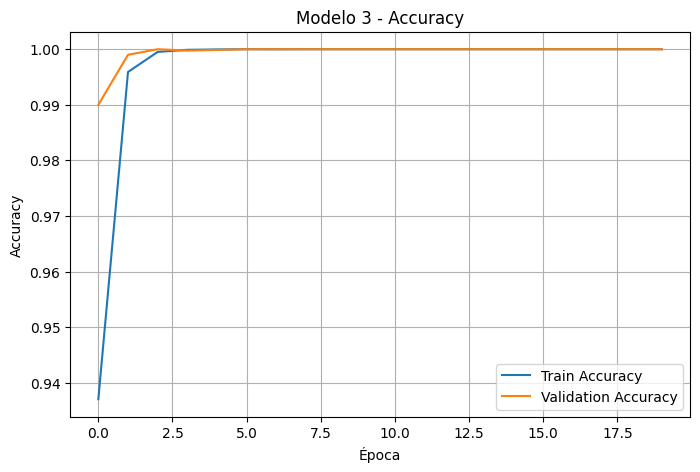

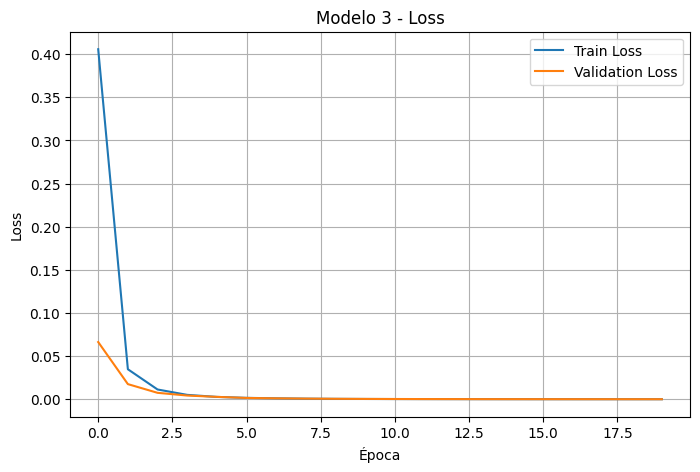

Época  1 | Train Acc: 0.9370 | Val Acc: 0.9900 | Train Loss: 0.405723 | Val Loss: 0.066290
Época  2 | Train Acc: 0.9959 | Val Acc: 0.9990 | Train Loss: 0.034761 | Val Loss: 0.017516
Época  3 | Train Acc: 0.9995 | Val Acc: 1.0000 | Train Loss: 0.011297 | Val Loss: 0.007431
Época  4 | Train Acc: 0.9999 | Val Acc: 0.9998 | Train Loss: 0.005062 | Val Loss: 0.004285
Época  5 | Train Acc: 1.0000 | Val Acc: 0.9999 | Train Loss: 0.002687 | Val Loss: 0.002742
Época  6 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.001604 | Val Loss: 0.001485
Época  7 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.001055 | Val Loss: 0.001053
Época  8 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000661 | Val Loss: 0.000722
Época  9 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000446 | Val Loss: 0.000494
Época 10 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000308 | Val Loss: 0.000363
Época 11 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000220 | Val Loss: 0.000266

In [ ]:
test_loss_3, test_acc_3 = model_MLP_3.evaluate(
    x_test_gray,
    y_test_one_hot
)

print(f'Precisión en el conjunto de prueba: {test_acc_3}. Pérdida: {test_loss_3}')

print(history_mlp_3.history.keys())

plt.figure(figsize=(8, 5))

plt.plot(history_mlp_3.history['accuracy'], label='Train Accuracy')
plt.plot(history_mlp_3.history['val_accuracy'], label='Validation Accuracy')

plt.title('Modelo 3 - Accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

#Loss
plt.figure(figsize=(8, 5))

plt.plot(history_mlp_3.history['loss'], label='Train Loss')
plt.plot(history_mlp_3.history['val_loss'], label='Validation Loss')

plt.title('Modelo 3 - Loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

#Eoch comparison
for epoch in range(len(history_mlp_3.history['accuracy'])):
    print(
        f"Época {epoch+1:2d} | "
        f"Train Acc: {history_mlp_3.history['accuracy'][epoch]:.4f} | "
        f"Val Acc: {history_mlp_3.history['val_accuracy'][epoch]:.4f} | "
        f"Train Loss: {history_mlp_3.history['loss'][epoch]:.6f} | "
        f"Val Loss: {history_mlp_3.history['val_loss'][epoch]:.6f}"
    )

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Precision: 1.0000
Recall:    1.0000
F1 Score:  0.9999
              precision    recall  f1-score   support

           0     1.0000    0.9995    0.9998      2003
           1     0.9995    1.0000    0.9998      2009
           2     1.0000    1.0000    1.0000      1995
           3     1.0000    1.0000    1.0000      1980
           4     1.0000    1.0000    1.0000      2026
           5     1.0000    1.0000    1.0000      1995
           6     1.0000    1.0000    1.0000      2020
           7     1.0000    1.0000    1.0000      1947
           8     1.0000    1.0000    1.0000      2000
           9     1.0000    1.0000    1.0000      2025

    accuracy                         1.0000     20000
   macro avg     1.0000    1.0000    1.0000     20000
weighted avg     1.0000    1.0000    0.9999     20000



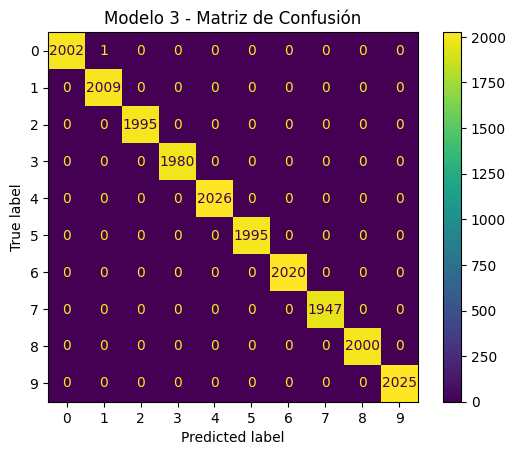

In [ ]:
y_pred_prob3 = model_MLP_3.predict(x_test_gray)
import numpy as np

y_pred = np.argmax(y_pred_prob3, axis=1)
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


print(classification_report(
    y_test,
    y_pred,
    digits=4
))



cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title('Modelo 3 - Matriz de Confusión')
plt.show()